# Digital Image Processing – Assignment 1
**Name:** Abisha
**ID:** 232031056

Colour image shape: (512, 512, 3)
Grayscale image shape: (512, 512)


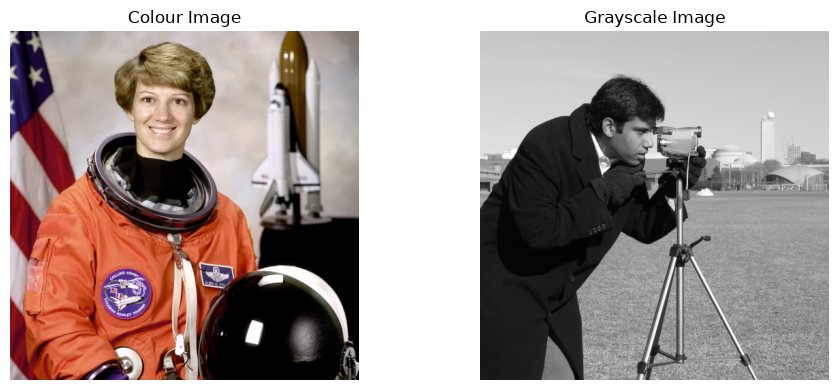

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import urllib.request

REPO_IMG_BASE = "https://raw.githubusercontent.com/id-232031056/dip/main/images"

def load_image(filename, gray=False):
    url = f"{REPO_IMG_BASE}/{filename}"
    try:
        resp = urllib.request.urlopen(url, timeout=10)
        arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
        flag = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
        img = cv2.imdecode(arr, flag)
        if img is not None:
            if not gray:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            return img
    except Exception:
        pass
    from skimage import data
    if gray:
        return data.camera()
    return data.astronaut()

# Load colour test image
img_rgb = load_image("test_color.png", gray=False)
# Load grayscale test image
img_gray = load_image("test_gray.png", gray=True)

print("Colour image shape:", img_rgb.shape)
print("Grayscale image shape:", img_gray.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1,2,1); plt.imshow(img_rgb); plt.title("Colour Image"); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(img_gray, cmap='gray'); plt.title("Grayscale Image"); plt.axis('off')
plt.tight_layout(); plt.show()

## Task 1.1 – RGB ↔ HSI Colour Model Conversion

The HSI model separates colour information into Hue (H), Saturation (S), and Intensity (I):
- **I** = (R + G + B) / 3
- **S** = 1 − 3 · min(R, G, B) / (R + G + B)
- **H** = θ if B ≤ G, else 360° − θ, where θ = arccos[0.5((R−G)+(R−B)) / √((R−G)² + (R−B)(G−B))]

RGB values are normalised to [0, 1] first. A small epsilon handles divide-by-zero for achromatic (gray/black) pixels.

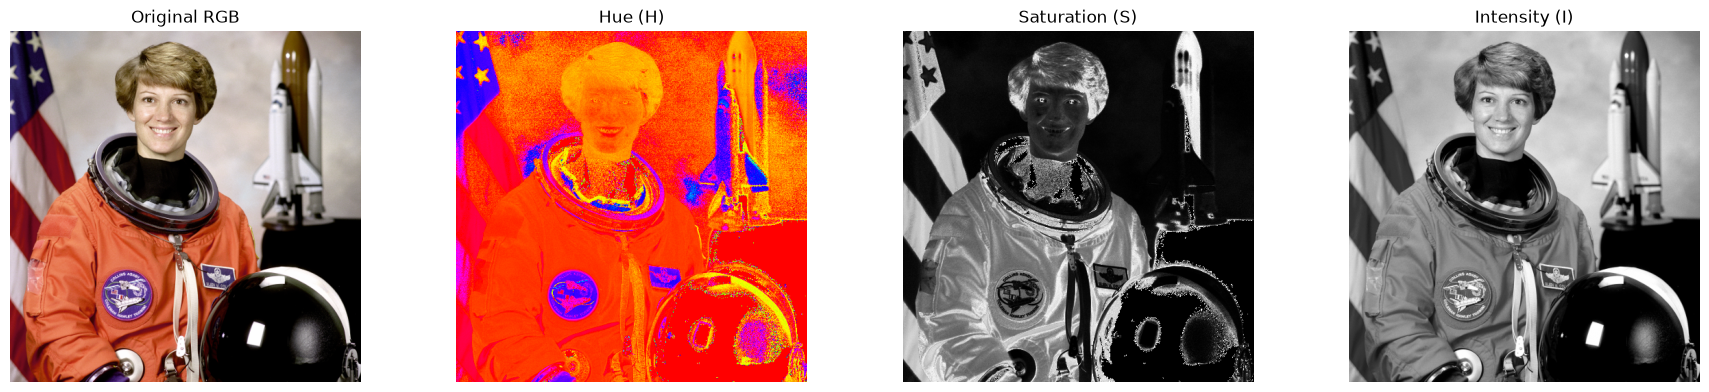

H range: [0.00, 359.61] degrees
S range: [0.0000, 1.0000]
I range: [0.0000, 1.0000]


In [2]:
def rgb_to_hsi(image):
    """Convert RGB image to HSI colour model manually.
    Input: uint8 RGB image [0,255]. Output: H in [0,360], S in [0,1], I in [0,1]."""
    img = image.astype(np.float64) / 255.0
    R, G, B = img[:,:,0], img[:,:,1], img[:,:,2]
    eps = 1e-10  # avoid division by zero

    # Intensity
    I = (R + G + B) / 3.0

    # Saturation
    min_rgb = np.minimum(np.minimum(R, G), B)
    denom = R + G + B + eps
    S = 1.0 - 3.0 * min_rgb / denom
    # For black pixels (R+G+B=0), S is undefined -> set to 0
    S[R + G + B < eps] = 0.0

    # Hue
    num = 0.5 * ((R - G) + (R - B))
    den = np.sqrt((R - G)**2 + (R - B) * (G - B) + eps)
    theta = np.arccos(np.clip(num / den, -1.0, 1.0))
    theta = np.degrees(theta)

    H = np.where(B <= G, theta, 360.0 - theta)
    # For achromatic pixels (S ≈ 0), H is undefined -> set to 0
    H[S < eps] = 0.0

    return H, S, I

H, S, I = rgb_to_hsi(img_rgb)

# Display H, S, I components
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(img_rgb); axes[0].set_title("Original RGB"); axes[0].axis('off')
axes[1].imshow(H, cmap='hsv'); axes[1].set_title("Hue (H)"); axes[1].axis('off')
im2 = axes[2].imshow(S, cmap='gray', vmin=0, vmax=1); axes[2].set_title("Saturation (S)"); axes[2].axis('off')
im3 = axes[3].imshow(I, cmap='gray', vmin=0, vmax=1); axes[3].set_title("Intensity (I)"); axes[3].axis('off')
plt.tight_layout(); plt.show()

print(f"H range: [{H.min():.2f}, {H.max():.2f}] degrees")
print(f"S range: [{S.min():.4f}, {S.max():.4f}]")
print(f"I range: [{I.min():.4f}, {I.max():.4f}]")

Max absolute error (RGB reconstruction): 1.00
Mean absolute error: 0.5885


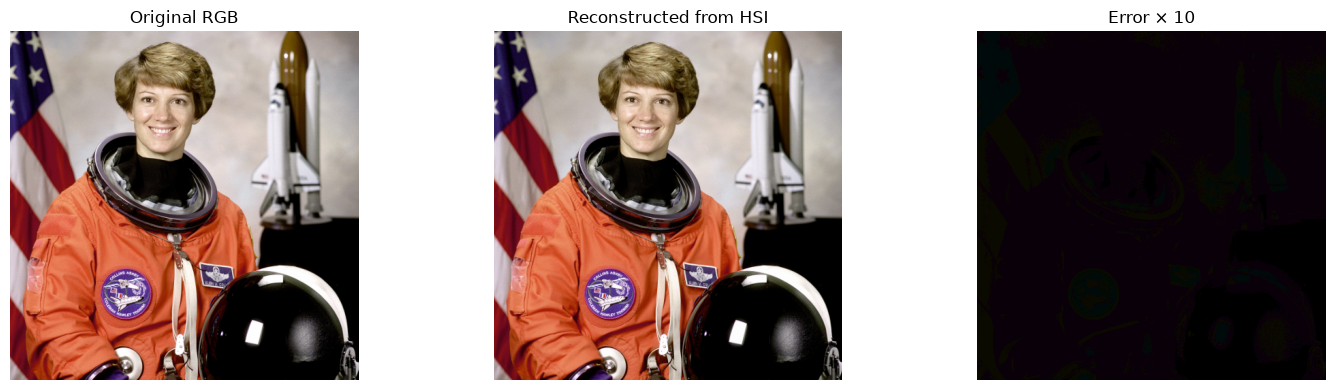

In [3]:
def hsi_to_rgb(H, S, I):
    """Convert HSI back to RGB. H in [0,360], S in [0,1], I in [0,1].
    Returns uint8 RGB image [0,255]."""
    H_rad = np.deg2rad(H)
    R = np.zeros_like(H)
    G = np.zeros_like(H)
    B = np.zeros_like(H)

    # Sector 1: 0 <= H < 120
    mask1 = (H >= 0) & (H < 120)
    H1 = H_rad[mask1]
    B[mask1] = I[mask1] * (1 - S[mask1])
    R[mask1] = I[mask1] * (1 + S[mask1] * np.cos(H1) / (np.cos(np.deg2rad(60) - H1) + 1e-10))
    G[mask1] = 3 * I[mask1] - (R[mask1] + B[mask1])

    # Sector 2: 120 <= H < 240
    mask2 = (H >= 120) & (H < 240)
    H2 = H_rad[mask2] - np.deg2rad(120)
    R[mask2] = I[mask2] * (1 - S[mask2])
    G[mask2] = I[mask2] * (1 + S[mask2] * np.cos(H2) / (np.cos(np.deg2rad(60) - H2) + 1e-10))
    B[mask2] = 3 * I[mask2] - (R[mask2] + G[mask2])

    # Sector 3: 240 <= H < 360
    mask3 = (H >= 240) & (H < 360)
    H3 = H_rad[mask3] - np.deg2rad(240)
    G[mask3] = I[mask3] * (1 - S[mask3])
    B[mask3] = I[mask3] * (1 + S[mask3] * np.cos(H3) / (np.cos(np.deg2rad(60) - H3) + 1e-10))
    R[mask3] = 3 * I[mask3] - (G[mask3] + B[mask3])

    rgb = np.stack([R, G, B], axis=-1)
    rgb = np.clip(rgb * 255, 0, 255).astype(np.uint8)
    return rgb

# Reconstruct RGB from HSI
reconstructed = hsi_to_rgb(H, S, I)

# Compute error
error = np.abs(img_rgb.astype(np.float64) - reconstructed.astype(np.float64))
print(f"Max absolute error (RGB reconstruction): {error.max():.2f}")
print(f"Mean absolute error: {error.mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_rgb); axes[0].set_title("Original RGB"); axes[0].axis('off')
axes[1].imshow(reconstructed); axes[1].set_title("Reconstructed from HSI"); axes[1].axis('off')
axes[2].imshow((error * 10).astype(np.uint8)); axes[2].set_title("Error × 10"); axes[2].axis('off')
plt.tight_layout(); plt.show()

## Task 1.2 – Affine Transformations

Affine transformations map pixels using a 3×3 homogeneous matrix. We use **inverse mapping**:
for each pixel (x', y') in the output, compute the source coordinate (x, y) = M⁻¹ · (x', y', 1)ᵀ.
This avoids holes in the output. Common affine transforms include translation, rotation, scaling, and shearing.

Translation matrix:
 [[ 1.  0. 50.]
 [ 0.  1. 30.]
 [ 0.  0.  1.]]

Rotation matrix (30°):
 [[  0.866   -0.5    162.2975]
 [  0.5      0.866  -93.7025]
 [  0.       0.       1.    ]]

Scaling matrix (sx=0.7, sy=1.3):
 [[0.7 0.  0. ]
 [0.  1.3 0. ]
 [0.  0.  1. ]]

Shear matrix (shx=0.3, shy=0.1):
 [[1.  0.3 0. ]
 [0.1 1.  0. ]
 [0.  0.  1. ]]

Combined (rotation + scaling) matrix:
 [[  0.6062  -0.65   162.2975]
 [  0.35     1.1258 -93.7025]
 [  0.       0.       1.    ]]


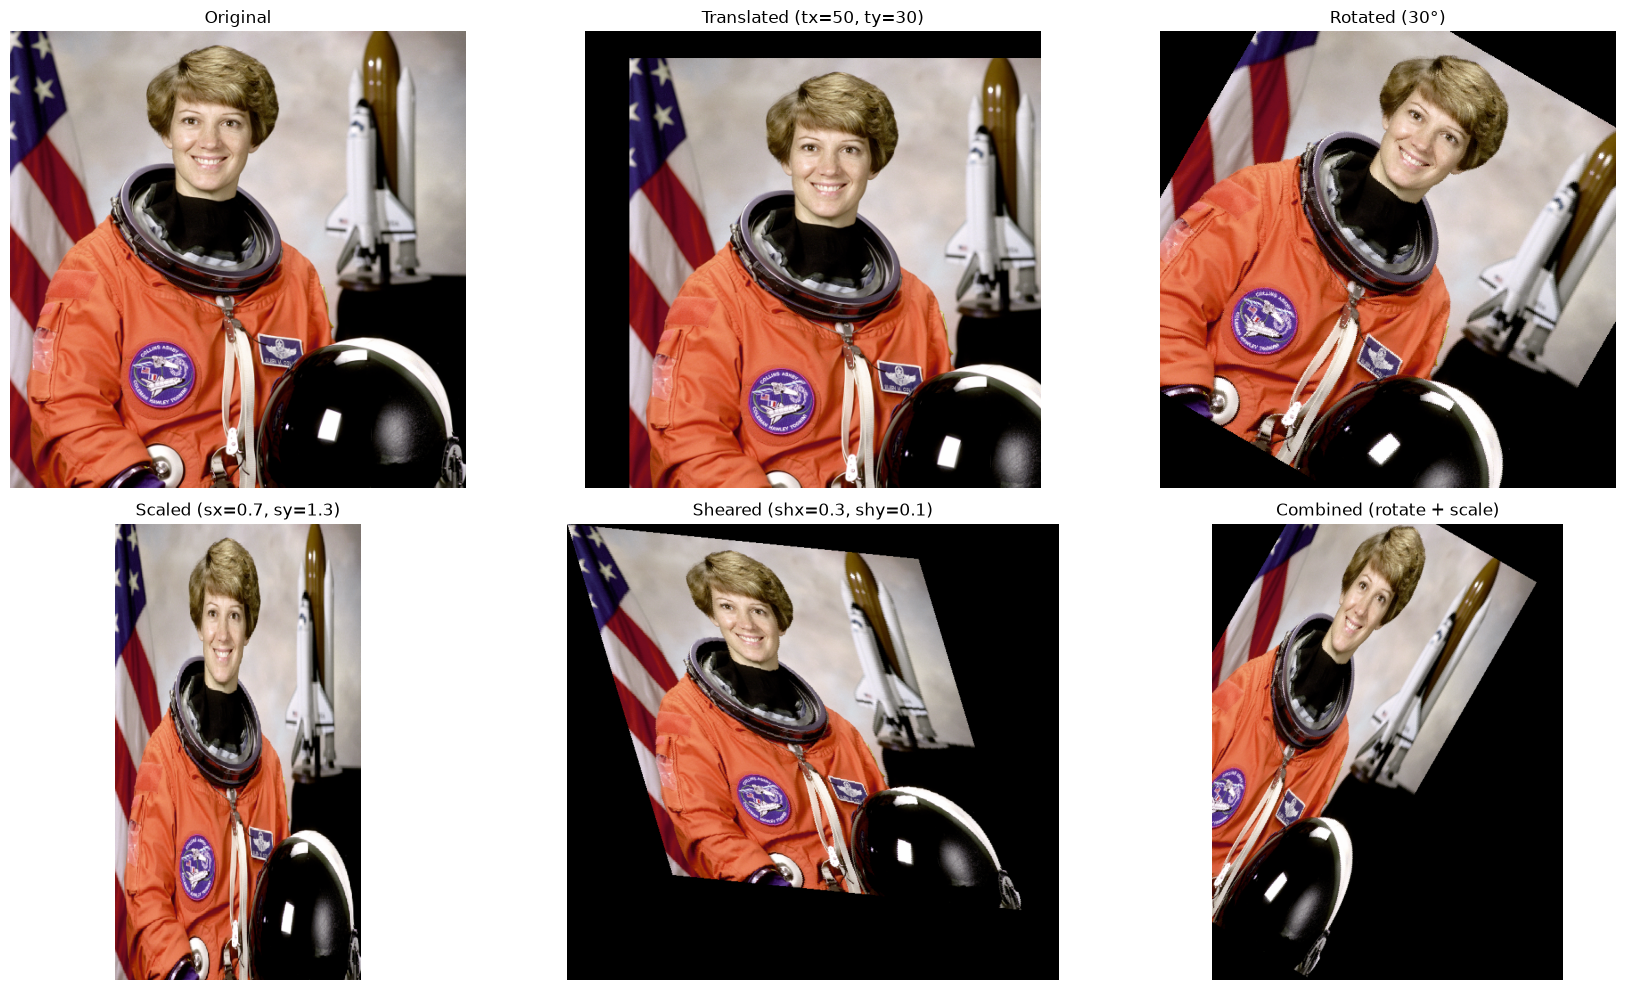

In [4]:
def apply_affine(image, M, output_shape=None):
    """Apply affine transformation using INVERSE MAPPING.
    M is 3x3 forward transformation matrix. We compute M_inv for inverse mapping.
    Uses nearest-neighbour interpolation for simplicity (bilinear in Task 1.3)."""
    h, w = image.shape[:2]
    if output_shape is None:
        output_shape = (h, w)
    oh, ow = output_shape

    M_inv = np.linalg.inv(M)

    if image.ndim == 3:
        output = np.zeros((oh, ow, image.shape[2]), dtype=image.dtype)
    else:
        output = np.zeros((oh, ow), dtype=image.dtype)

    # Create grid of output coordinates
    yy, xx = np.meshgrid(np.arange(oh), np.arange(ow), indexing='ij')
    coords = np.stack([xx.ravel(), yy.ravel(), np.ones(oh * ow)], axis=0)  # 3 x N

    # Inverse map to source coordinates
    src = M_inv @ coords  # 3 x N
    src_x = np.round(src[0]).astype(int)
    src_y = np.round(src[1]).astype(int)

    # Mask valid coordinates
    valid = (src_x >= 0) & (src_x < w) & (src_y >= 0) & (src_y < h)
    out_x = xx.ravel()[valid]
    out_y = yy.ravel()[valid]

    output[out_y, out_x] = image[src_y[valid], src_x[valid]]
    return output

# Use a smaller image for faster demo
img_affine = img_rgb
h, w = img_affine.shape[:2]

# --- Translation ---
tx, ty = 50, 30
M_translate = np.array([[1, 0, tx],
                         [0, 1, ty],
                         [0, 0,  1]], dtype=np.float64)
translated = apply_affine(img_affine, M_translate)
print("Translation matrix:\n", M_translate)

# --- Rotation (30 degrees about center) ---
angle = 30
theta = np.deg2rad(angle)
cx, cy = w / 2, h / 2
# Translate to origin, rotate, translate back
M_to_origin = np.array([[1, 0, -cx], [0, 1, -cy], [0, 0, 1]])
M_rotate = np.array([[np.cos(theta), -np.sin(theta), 0],
                      [np.sin(theta),  np.cos(theta), 0],
                      [0,              0,             1]])
M_back = np.array([[1, 0, cx], [0, 1, cy], [0, 0, 1]])
M_rot_full = M_back @ M_rotate @ M_to_origin
rotated = apply_affine(img_affine, M_rot_full)
print(f"\nRotation matrix ({angle}°):\n", np.round(M_rot_full, 4))

# --- Scaling ---
sx, sy = 0.7, 1.3
M_scale = np.array([[sx, 0, 0],
                     [0, sy, 0],
                     [0,  0, 1]], dtype=np.float64)
scaled = apply_affine(img_affine, M_scale, output_shape=(int(h*sy), int(w*sx)))
print(f"\nScaling matrix (sx={sx}, sy={sy}):\n", M_scale)

# --- Shearing ---
shx, shy = 0.3, 0.1
M_shear = np.array([[1,   shx, 0],
                     [shy, 1,   0],
                     [0,   0,   1]], dtype=np.float64)
sheared = apply_affine(img_affine, M_shear, output_shape=(int(h*1.3), int(w*1.4)))
print(f"\nShear matrix (shx={shx}, shy={shy}):\n", M_shear)

# --- Combined transformation ---
M_combined = M_back @ M_rotate @ M_to_origin @ M_scale
combined = apply_affine(img_affine, M_combined, output_shape=(int(h*1.3), int(w*1.0)))
print(f"\nCombined (rotation + scaling) matrix:\n", np.round(M_combined, 4))

# Display all results
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes[0,0].imshow(img_affine); axes[0,0].set_title("Original"); axes[0,0].axis('off')
axes[0,1].imshow(translated); axes[0,1].set_title(f"Translated (tx={tx}, ty={ty})"); axes[0,1].axis('off')
axes[0,2].imshow(rotated); axes[0,2].set_title(f"Rotated ({angle}°)"); axes[0,2].axis('off')
axes[1,0].imshow(scaled); axes[1,0].set_title(f"Scaled (sx={sx}, sy={sy})"); axes[1,0].axis('off')
axes[1,1].imshow(sheared); axes[1,1].set_title(f"Sheared (shx={shx}, shy={shy})"); axes[1,1].axis('off')
axes[1,2].imshow(combined); axes[1,2].set_title("Combined (rotate + scale)"); axes[1,2].axis('off')
plt.tight_layout(); plt.show()

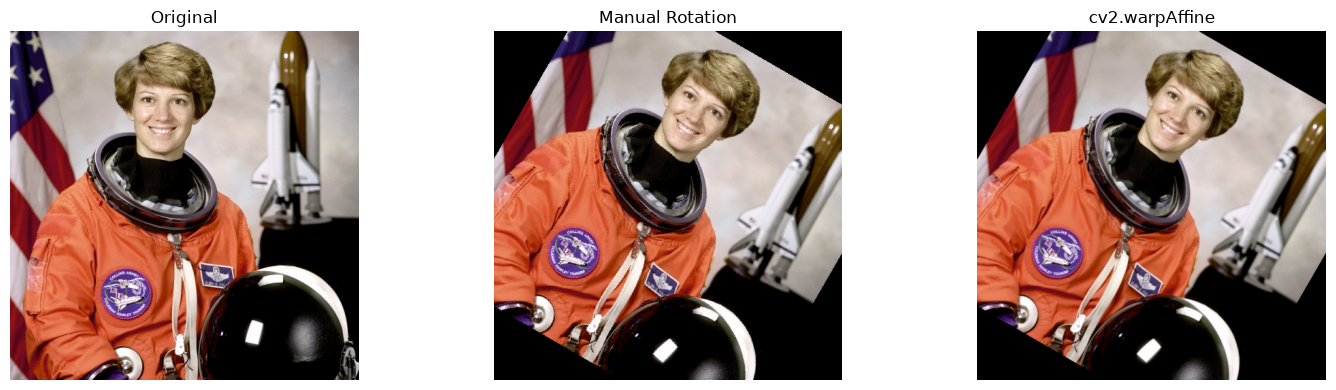

Manual uses nearest-neighbour; cv2 uses bilinear by default, so slight differences are expected.


In [5]:
# Verification: compare rotation with cv2.warpAffine
M_cv2 = M_rot_full[:2, :]  # cv2 uses 2x3 matrix
rotated_cv2 = cv2.warpAffine(img_affine, M_cv2, (w, h))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_affine); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(rotated); axes[1].set_title("Manual Rotation"); axes[1].axis('off')
axes[2].imshow(rotated_cv2); axes[2].set_title("cv2.warpAffine"); axes[2].axis('off')
plt.tight_layout(); plt.show()
print("Manual uses nearest-neighbour; cv2 uses bilinear by default, so slight differences are expected.")

## Task 1.3 – Spatial Interpolation

Interpolation estimates pixel values at non-integer coordinates during geometric transformations:
- **Nearest-neighbour**: uses the value of the closest pixel (fast, blocky).
- **Bilinear**: weighted average of the 4 nearest pixels (smoother).
- **Bicubic**: weighted average of 16 nearest pixels using cubic kernel (smoothest, preserves edges better).

In [6]:
def resize_nearest(image, scale):
    """Resize image using nearest-neighbour interpolation."""
    h, w = image.shape[:2]
    new_h, new_w = int(h * scale), int(w * scale)
    if image.ndim == 3:
        output = np.zeros((new_h, new_w, image.shape[2]), dtype=image.dtype)
    else:
        output = np.zeros((new_h, new_w), dtype=image.dtype)

    for i in range(new_h):
        for j in range(new_w):
            src_y = min(int(round(i / scale)), h - 1)
            src_x = min(int(round(j / scale)), w - 1)
            output[i, j] = image[src_y, src_x]
    return output

def resize_bilinear(image, scale):
    """Resize image using bilinear interpolation."""
    h, w = image.shape[:2]
    new_h, new_w = int(h * scale), int(w * scale)
    img_f = image.astype(np.float64)
    if image.ndim == 3:
        output = np.zeros((new_h, new_w, image.shape[2]), dtype=np.float64)
    else:
        output = np.zeros((new_h, new_w), dtype=np.float64)

    for i in range(new_h):
        for j in range(new_w):
            # Map to source coordinates
            src_y = i / scale
            src_x = j / scale
            y0 = int(np.floor(src_y))
            x0 = int(np.floor(src_x))
            y1 = min(y0 + 1, h - 1)
            x1 = min(x0 + 1, w - 1)
            y0 = min(y0, h - 1)
            x0 = min(x0, w - 1)

            dy = src_y - y0
            dx = src_x - x0

            # Bilinear interpolation
            val = (1 - dy) * (1 - dx) * img_f[y0, x0] + \
                  (1 - dy) * dx * img_f[y0, x1] + \
                  dy * (1 - dx) * img_f[y1, x0] + \
                  dy * dx * img_f[y1, x1]
            output[i, j] = val

    return np.clip(output, 0, 255).astype(np.uint8)

def cubic_weight(t):
    """Cubic interpolation kernel (a=-0.5, Keys' kernel)."""
    t = abs(t)
    if t <= 1:
        return 1.5 * t**3 - 2.5 * t**2 + 1
    elif t < 2:
        return -0.5 * t**3 + 2.5 * t**2 - 4 * t + 2
    return 0.0

def resize_bicubic(image, scale):
    """Resize image using bicubic interpolation."""
    h, w = image.shape[:2]
    new_h, new_w = int(h * scale), int(w * scale)
    img_f = image.astype(np.float64)
    if image.ndim == 3:
        output = np.zeros((new_h, new_w, image.shape[2]), dtype=np.float64)
    else:
        output = np.zeros((new_h, new_w), dtype=np.float64)

    for i in range(new_h):
        for j in range(new_w):
            src_y = i / scale
            src_x = j / scale
            y0 = int(np.floor(src_y))
            x0 = int(np.floor(src_x))

            val = 0.0
            for m in range(-1, 3):
                for n in range(-1, 3):
                    yi = np.clip(y0 + m, 0, h - 1)
                    xi = np.clip(x0 + n, 0, w - 1)
                    wy = cubic_weight(src_y - (y0 + m))
                    wx = cubic_weight(src_x - (x0 + n))
                    val = val + img_f[yi, xi] * wy * wx
            output[i, j] = val
    return np.clip(output, 0, 255).astype(np.uint8)

# Use a small crop for speed (bicubic with loops is slow)
crop = img_gray[:64, :64]
print("Crop size:", crop.shape)

# Upscale 4x
up_nn = resize_nearest(crop, 4.0)
up_bl = resize_bilinear(crop, 4.0)
up_bc = resize_bicubic(crop, 4.0)

# Downscale 0.5x
down_nn = resize_nearest(img_gray, 0.5)
down_bl = resize_bilinear(img_gray, 0.5)
down_bc = resize_bicubic(img_gray, 0.5)

print("Upscaled (4x) shapes:", up_nn.shape, up_bl.shape, up_bc.shape)
print("Downscaled (0.5x) shapes:", down_nn.shape, down_bl.shape, down_bc.shape)

Crop size: (64, 64)


Upscaled (4x) shapes: (256, 256) (256, 256) (256, 256)
Downscaled (0.5x) shapes: (256, 256) (256, 256) (256, 256)


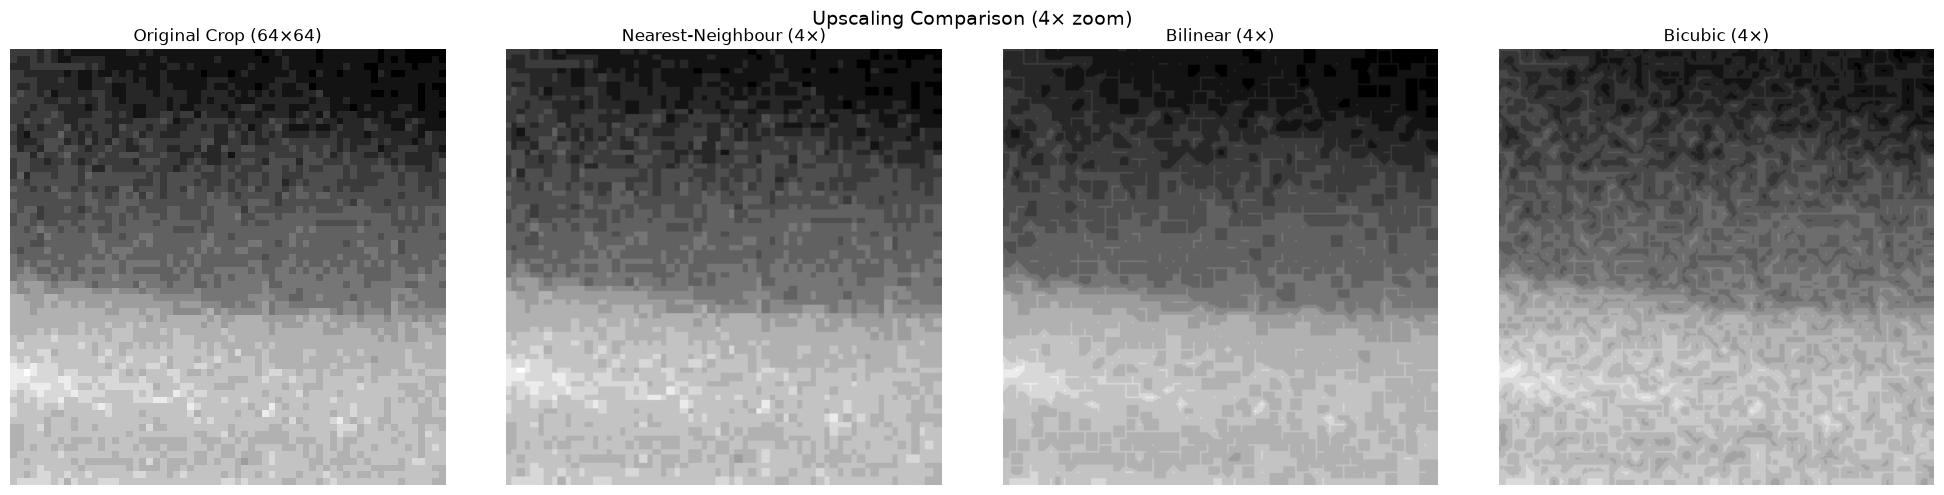

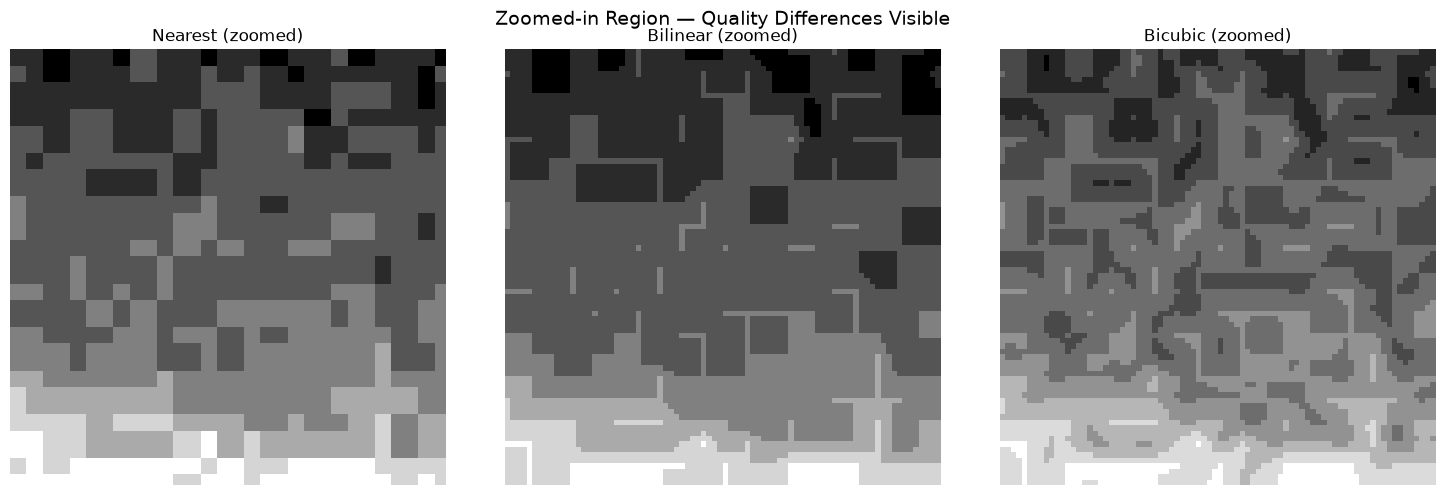

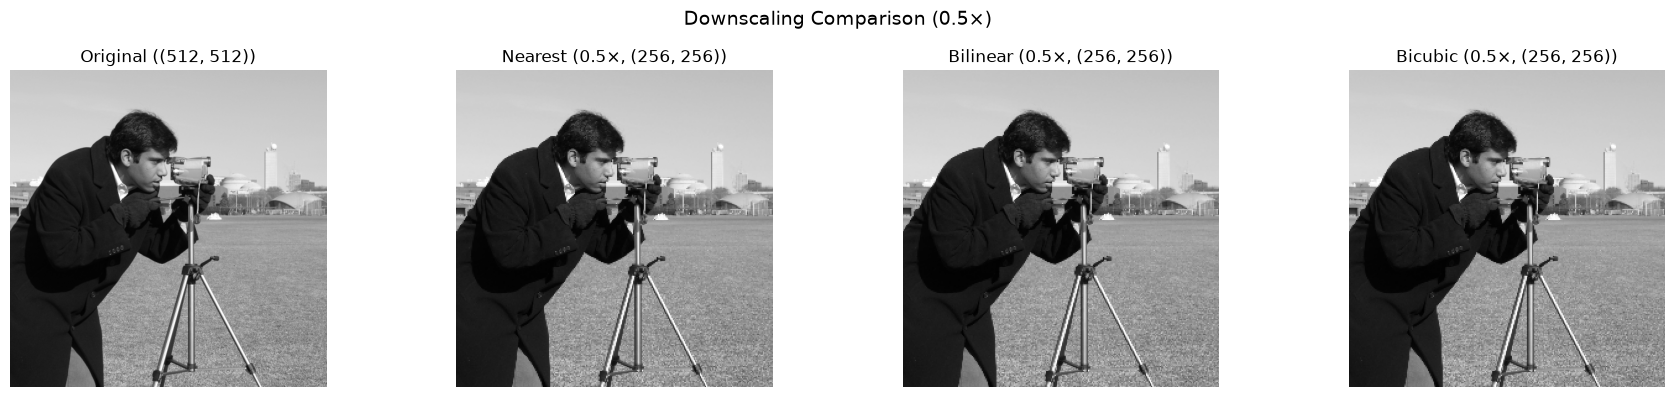

In [7]:
# Display upscaled results (zoomed crop)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(crop, cmap='gray'); axes[0].set_title("Original Crop (64×64)"); axes[0].axis('off')
axes[1].imshow(up_nn, cmap='gray'); axes[1].set_title("Nearest-Neighbour (4×)"); axes[1].axis('off')
axes[2].imshow(up_bl, cmap='gray'); axes[2].set_title("Bilinear (4×)"); axes[2].axis('off')
axes[3].imshow(up_bc, cmap='gray'); axes[3].set_title("Bicubic (4×)"); axes[3].axis('off')
plt.suptitle("Upscaling Comparison (4× zoom)", fontsize=14)
plt.tight_layout(); plt.show()

# Show zoomed-in region to see quality differences
region = slice(80, 160), slice(80, 160)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(up_nn[region[0], region[1]], cmap='gray'); axes[0].set_title("Nearest (zoomed)"); axes[0].axis('off')
axes[1].imshow(up_bl[region[0], region[1]], cmap='gray'); axes[1].set_title("Bilinear (zoomed)"); axes[1].axis('off')
axes[2].imshow(up_bc[region[0], region[1]], cmap='gray'); axes[2].set_title("Bicubic (zoomed)"); axes[2].axis('off')
plt.suptitle("Zoomed-in Region — Quality Differences Visible", fontsize=14)
plt.tight_layout(); plt.show()

# Display downscaled results
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title(f"Original ({img_gray.shape})"); axes[0].axis('off')
axes[1].imshow(down_nn, cmap='gray'); axes[1].set_title(f"Nearest (0.5×, {down_nn.shape})"); axes[1].axis('off')
axes[2].imshow(down_bl, cmap='gray'); axes[2].set_title(f"Bilinear (0.5×, {down_bl.shape})"); axes[2].axis('off')
axes[3].imshow(down_bc, cmap='gray'); axes[3].set_title(f"Bicubic (0.5×, {down_bc.shape})"); axes[3].axis('off')
plt.suptitle("Downscaling Comparison (0.5×)", fontsize=14)
plt.tight_layout(); plt.show()

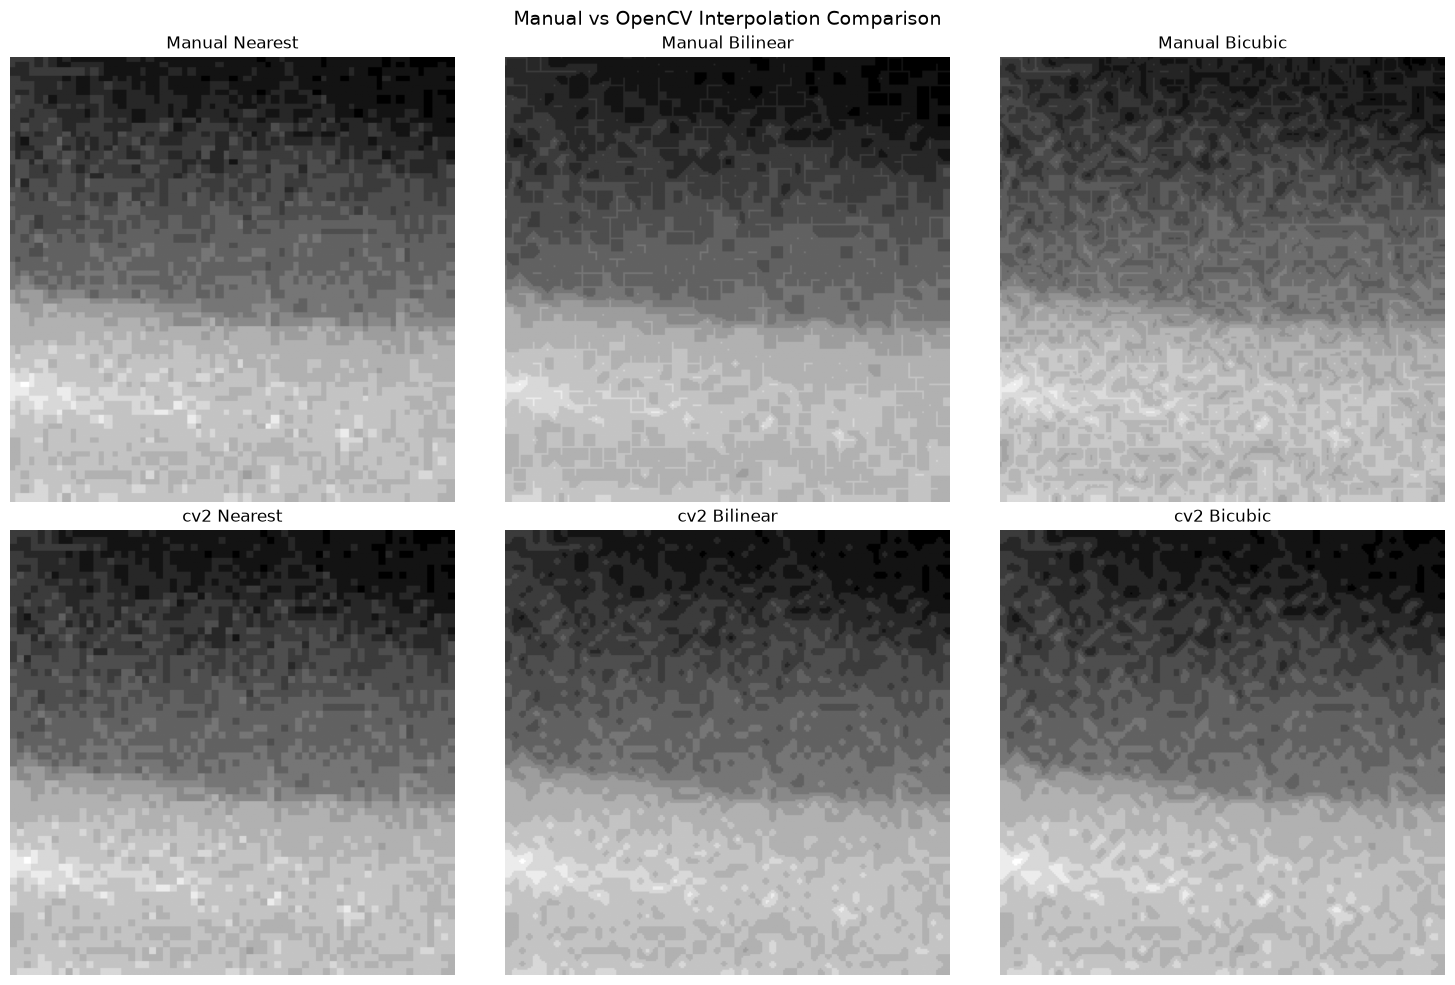

In [8]:
# Optional: Compare with cv2.resize
cv_nn = cv2.resize(crop, (crop.shape[1]*4, crop.shape[0]*4), interpolation=cv2.INTER_NEAREST)
cv_bl = cv2.resize(crop, (crop.shape[1]*4, crop.shape[0]*4), interpolation=cv2.INTER_LINEAR)
cv_bc = cv2.resize(crop, (crop.shape[1]*4, crop.shape[0]*4), interpolation=cv2.INTER_CUBIC)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0,0].imshow(up_nn, cmap='gray'); axes[0,0].set_title("Manual Nearest"); axes[0,0].axis('off')
axes[0,1].imshow(up_bl, cmap='gray'); axes[0,1].set_title("Manual Bilinear"); axes[0,1].axis('off')
axes[0,2].imshow(up_bc, cmap='gray'); axes[0,2].set_title("Manual Bicubic"); axes[0,2].axis('off')
axes[1,0].imshow(cv_nn, cmap='gray'); axes[1,0].set_title("cv2 Nearest"); axes[1,0].axis('off')
axes[1,1].imshow(cv_bl, cmap='gray'); axes[1,1].set_title("cv2 Bilinear"); axes[1,1].axis('off')
axes[1,2].imshow(cv_bc, cmap='gray'); axes[1,2].set_title("cv2 Bicubic"); axes[1,2].axis('off')
plt.suptitle("Manual vs OpenCV Interpolation Comparison", fontsize=14)
plt.tight_layout(); plt.show()

## Conclusion

In this assignment, we implemented three fundamental image processing operations:

1. **RGB ↔ HSI Conversion** (Task 1.1): Manual conversion using the standard trigonometric formulas, with proper handling of edge cases (black/gray pixels). The inverse conversion produces a reconstruction very close to the original.
2. **Affine Transformations** (Task 1.2): Translation, rotation, scaling, shearing, and composition using 3×3 homogeneous matrices with inverse mapping to avoid output holes.
3. **Spatial Interpolation** (Task 1.3): Nearest-neighbour, bilinear, and bicubic interpolation for image resizing. Bilinear produces smoother results than nearest-neighbour, while bicubic gives the best quality at higher computational cost.